# So sánh trực quan các ứng viên site Mặt Trăng

Notebook này giúp nhóm xem vị trí, ROI đã có, trạng thái coverage và quy mô 5 lớp raster trước khi chốt roster. **Nó không chọn site và không hiển thị raster địa hình đầy đủ.**

**Cập nhật review 14-11-2026:** các bảng horizon có bất nhất giữa các bán kính chưa được giải thích; chưa có script/profile theo bin để tái lập p95. Hình p95 bên dưới chỉ vẽ lại số đã báo cáo, không được dùng để chốt ngưỡng, độ phân giải hoặc bán kính chân trời. Xem [cảnh báo và điều kiện sử dụng](../docs/data-mining-plan.md#bounded-80-m--20-m-horizon-profile-comparison).

Để chạy lại, cần Jupyter Notebook, Python, `pandas` và `matplotlib`; notebook không tự tải dữ liệu hay cài package.

- Sáu site có kiểm tra pixel 9×9: Site01, Site04, Site07, Site11, Site20, Site23. Site20v2 là phiên bản sản phẩm thay thế; không phải site thứ bảy.
- Site06, Site42 và Haworth mới được kiểm tra metadata/kích thước HTTP HEAD; chưa đọc pixel.
- ROI chỉ có đường viền giản lược 10 m để trình bày từ 4 bundle nhỏ của PGDA: Site01/04/07/11. ROI này không phải ranh giới landing zone. Điểm tham chiếu Data Book có thể nằm ngoài ROI. Site06 có link ROI trên trang nhưng trả 404; Site20/Site23 không có bundle hợp lệ ở đường dẫn kiểm tra; Site42/Haworth không có link ROI trên trang.
- Hệ tọa độ overview là south-polar stereographic trên bán kính Mặt Trăng 1,737,400 m, tính từ tâm tham chiếu NASA Data Book. Các điểm chỉ là điểm tái lập/kiểm tra dữ liệu, không phải tọa độ hạ cánh.

Nguồn: [NASA PGDA product 78](https://pgda.gsfc.nasa.gov/products/78), [NASA Lunar Surface Data Book 2025](https://ntrs.nasa.gov/api/citations/20250002845/downloads/M2M-30044%20Lunar%20Surface%20Data%20Book%20Baseline_Final.pdf). Kích thước được kiểm tra 14 Nov 2026.

Chạy từ thư mục repository bằng `jupyter notebook notebooks/candidate-site-visual-review.ipynb`. Các hình và bảng trong file đã được render sẵn; notebook không tải raster khi chạy.

In [1]:
%matplotlib inline

In [2]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon as MplPolygon, Patch
from IPython.display import display

R_MOON = 1_737_400
regions = [{'site': 'Site01', 'name': 'Connecting Ridge', 'lat': -89.4632, 'lon': -137.49, 'mb': 204.90395, 'point': True, 'roi': 'available', 'elev': '1941.240–1946.973'}, {'site': 'Site04', 'name': 'Shackleton Rim', 'lat': -89.7668, 'lon': -171.87, 'mb': 204.903932, 'point': True, 'roi': 'available', 'elev': '758.054–785.745'}, {'site': 'Site06', 'name': 'Nobile Rim 1', 'lat': -85.4381, 'lon': 37.36667, 'mb': 320.127929, 'point': False, 'roi': 'listed_404', 'elev': '—'}, {'site': 'Site07', 'name': 'Peak near Shackleton', 'lat': -88.811, 'lon': 123.6901, 'mb': 204.903942, 'point': True, 'roi': 'available', 'elev': '1643.553–1647.301'}, {'site': 'Site11', 'name': 'de Gerlache Rim 1', 'lat': -88.6834, 'lon': -67.9321, 'mb': 204.90394, 'point': True, 'roi': 'available', 'elev': '1792.609–1794.521'}, {'site': 'Site20', 'name': 'Leibnitz Beta Plateau', 'lat': -85.4266, 'lon': 31.74276, 'mb': 204.90393, 'point': True, 'roi': 'missing', 'elev': '6393.463–6401.779'}, {'site': 'Site23', 'name': 'Malapert Massif', 'lat': -85.9948, 'lon': -0.23578, 'mb': 352.933976, 'point': True, 'roi': 'missing_404', 'elev': '4782.270–4785.751'}, {'site': 'Site42', 'name': 'de Gerlache-Kocher Massif', 'lat': -85.8296, 'lon': -116.322, 'mb': 320.127973, 'point': False, 'roi': 'no_link', 'elev': '—'}, {'site': 'Haworth', 'name': 'Haworth', 'lat': -86.7639, 'lon': -22.777, 'mb': 710.618745, 'point': False, 'roi': 'no_link', 'elev': '—'}]
roi_polygons = {'Site01': [[[-11647.5, -12507.5], [-11652.5, -12467.5], [-11562.5, -12407.5], [-11542.5, -12407.5], [-11522.5, -12432.5], [-11522.5, -12452.5], [-11572.5, -12512.5], [-11587.5, -12517.5], [-11602.5, -12482.5], [-11647.5, -12507.5]], [[-11537.5, -12622.5], [-11492.5, -12527.5], [-11502.5, -12482.5], [-11482.5, -12477.5], [-11447.5, -12512.5], [-11447.5, -12532.5], [-11467.5, -12532.5], [-11447.5, -12587.5], [-11482.5, -12602.5], [-11507.5, -12637.5], [-11537.5, -12622.5]], [[-11392.5, -12537.5], [-11392.5, -12517.5], [-11372.5, -12507.5], [-11372.5, -12472.5], [-11297.5, -12487.5], [-11337.5, -12502.5], [-11342.5, -12527.5], [-11392.5, -12537.5]], [[-11372.5, -12262.5], [-11337.5, -12177.5], [-11287.5, -12107.5], [-11267.5, -12112.5], [-11242.5, -12092.5], [-11242.5, -12062.5], [-11227.5, -12052.5], [-11212.5, -12072.5], [-11217.5, -12122.5], [-11277.5, -12202.5], [-11267.5, -12217.5], [-11292.5, -12252.5], [-11337.5, -12237.5], [-11372.5, -12262.5]], [[-11177.5, -12042.5], [-11152.5, -12012.5], [-11157.5, -11967.5], [-11132.5, -11907.5], [-11077.5, -11887.5], [-11072.5, -11872.5], [-11037.5, -11877.5], [-11007.5, -11857.5], [-11002.5, -11887.5], [-11027.5, -11912.5], [-11102.5, -11927.5], [-11117.5, -11992.5], [-11142.5, -12017.5], [-11142.5, -12052.5], [-11177.5, -12042.5]], [[-10887.5, -11737.5], [-10882.5, -11722.5], [-10797.5, -11712.5], [-10757.5, -11682.5], [-10742.5, -11682.5], [-10752.5, -11722.5], [-10727.5, -11717.5], [-10757.5, -11777.5], [-10792.5, -11787.5], [-10837.5, -11777.5], [-10887.5, -11737.5]], [[-10277.5, -11527.5], [-10252.5, -11497.5], [-10222.5, -11497.5], [-10212.5, -11557.5], [-10167.5, -11572.5], [-10172.5, -11587.5], [-10172.5, -11597.5], [-10167.5, -11607.5], [-10272.5, -11587.5], [-10247.5, -11552.5], [-10277.5, -11527.5]]], 'Site04': [[[-2827.5, -6792.5], [-2842.5, -6692.5], [-2822.5, -6697.5], [-2807.5, -6662.5], [-2822.5, -6537.5], [-2802.5, -6522.5], [-2782.5, -6577.5], [-2792.5, -6642.5], [-2822.5, -6712.5], [-2822.5, -6757.5], [-2802.5, -6787.5], [-2812.5, -6802.5], [-2827.5, -6792.5]], [[-2792.5, -6382.5], [-2757.5, -6292.5], [-2717.5, -6262.5], [-2712.5, -6277.5], [-2757.5, -6317.5], [-2772.5, -6352.5], [-2737.5, -6387.5], [-2762.5, -6407.5], [-2757.5, -6432.5], [-2772.5, -6427.5], [-2762.5, -6407.5], [-2782.5, -6367.5], [-2792.5, -6382.5]], [[-2702.5, -6157.5], [-2692.5, -6077.5], [-2647.5, -6052.5], [-2652.5, -6082.5], [-2677.5, -6092.5], [-2677.5, -6162.5], [-2702.5, -6157.5]], [[-2687.5, -5917.5], [-2667.5, -5902.5], [-2667.5, -5927.5], [-2627.5, -5952.5], [-2657.5, -6027.5], [-2657.5, -5977.5], [-2687.5, -5917.5]]], 'Site07': [[[30137.5, -20002.5], [30142.5, -19977.5], [30167.5, -19962.5], [30202.5, -20022.5], [30157.5, -20042.5], [30137.5, -20002.5]], [[29962.5, -20137.5], [29972.5, -20112.5], [29997.5, -20102.5], [30012.5, -20022.5], [30032.5, -20022.5], [30047.5, -20037.5], [30067.5, -20032.5], [30067.5, -20057.5], [30127.5, -20102.5], [30107.5, -20122.5], [30127.5, -20152.5], [30167.5, -20117.5], [30197.5, -20167.5], [30177.5, -20167.5], [30167.5, -20142.5], [30152.5, -20167.5], [30112.5, -20152.5], [30067.5, -20167.5], [30042.5, -20137.5], [29962.5, -20137.5]]], 'Site11': [[[-37672.5, 14902.5], [-37667.5, 14922.5], [-37642.5, 14927.5], [-37592.5, 14917.5], [-37577.5, 14897.5], [-37527.5, 14922.5], [-37482.5, 14917.5], [-37442.5, 14867.5], [-37457.5, 14837.5], [-37457.5, 14817.5], [-37452.5, 14812.5], [-37452.5, 14807.5], [-37452.5, 14802.5], [-37497.5, 14842.5], [-37502.5, 14832.5], [-37577.5, 14872.5], [-37607.5, 14867.5], [-37672.5, 14902.5]], [[-37437.5, 14767.5], [-37427.5, 14782.5], [-37392.5, 14767.5], [-37377.5, 14792.5], [-37352.5, 14727.5], [-37372.5, 14747.5], [-37397.5, 14737.5], [-37437.5, 14767.5]], [[-36617.5, 14492.5], [-36612.5, 14522.5], [-36582.5, 14517.5], [-36552.5, 14492.5], [-36552.5, 14472.5], [-36517.5, 14452.5], [-36517.5, 14432.5], [-36547.5, 14422.5], [-36562.5, 14437.5], [-36557.5, 14462.5], [-36617.5, 14492.5]], [[-36552.5, 14377.5], [-36552.5, 14392.5], [-36517.5, 14412.5], [-36477.5, 14312.5], [-36552.5, 14377.5]]]}

def polar_xy(lat_deg, lon_deg):
    # South-polar stereographic, spherical Moon; matches the ROI .prj parameters.
    phi = math.radians(lat_deg)
    lam = math.radians(lon_deg)
    rho = 2 * R_MOON * math.tan(math.pi/4 + phi/2)
    return rho * math.sin(lam), rho * math.cos(lam)

for r in regions:
    r['x_m'], r['y_m'] = polar_xy(r['lat'], r['lon'])
    r['screen'] = '9×9 pixel checks' if r['point'] else 'metadata only'

df = pd.DataFrame(regions)
display(df[['site','name','lat','lon','screen','roi','mb','elev']].rename(columns={'site':'Site','name':'Tên Data Book','lat':'Vĩ độ','lon':'Kinh độ','screen':'Kiểm tra','roi':'ROI','mb':'5 lớp (MB)','elev':'Cao độ cửa sổ 5 m (m)'}).round({'5 lớp (MB)':1}))

,Site,Tên Data Book,Vĩ độ,Kinh độ,Kiểm tra,ROI,5 lớp (MB),Cao độ cửa sổ 5 m (m)
0,Site01,Connecting Ridge,-89.4632,-137.49000,9×9 pixel checks,available,204.9,1941.240–1946.973
1,Site04,Shackleton Rim,-89.7668,-171.87000,9×9 pixel checks,available,204.9,758.054–785.745
2,Site06,Nobile Rim 1,-85.4381,37.36667,metadata only,listed_404,320.1,—
3,Site07,Peak near Shackleton,-88.8110,123.69010,9×9 pixel checks,available,204.9,1643.553–1647.301
4,Site11,de Gerlache Rim 1,-88.6834,-67.93210,9×9 pixel checks,available,204.9,1792.609–1794.521
5,Site20,Leibnitz Beta Plateau,-85.4266,31.74276,9×9 pixel checks,missing,204.9,6393.463–6401.779
6,Site23,Malapert Massif,-85.9948,-0.23578,9×9 pixel checks,missing_404,352.9,4782.270–4785.751
7,Site42,de Gerlache-Kocher Massif,-85.8296,-116.32200,metadata only,no_link,320.1,—
8,Haworth,Haworth,-86.7639,-22.77700,metadata only,no_link,710.6,—


## 1. Bản đồ vị trí ở cực Nam

Mỗi ký hiệu là tâm tham chiếu Data Book. Vòng tròn nét đứt biểu thị xấp xỉ ranh 80°S của bộ PGDA 90 80S; vùng này giúp thấy độ phân tán, không biểu thị footprint của raster cục bộ.

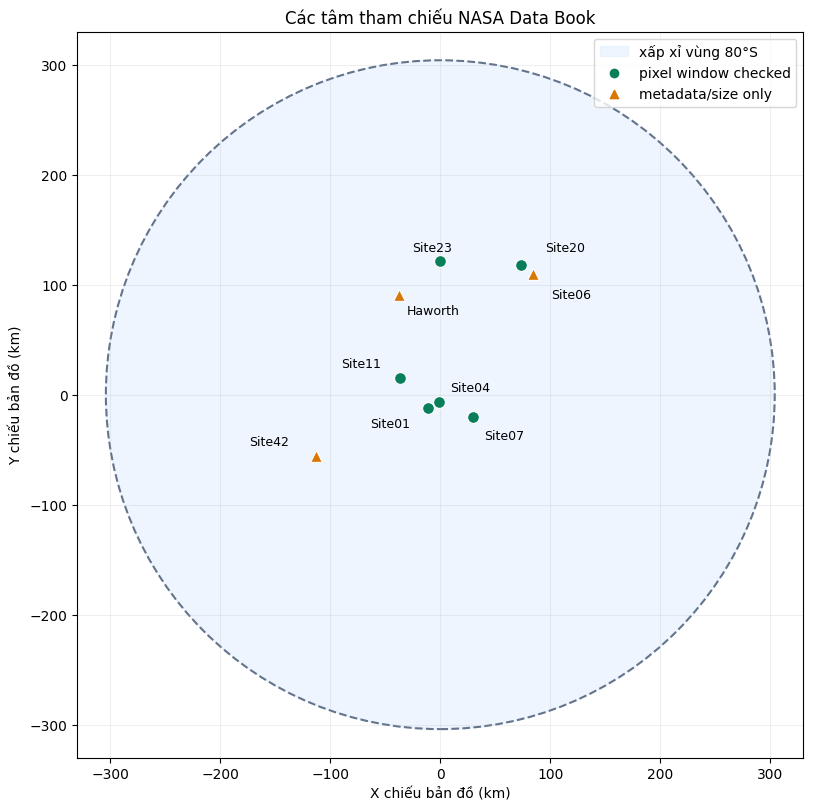

In [3]:
fig, ax = plt.subplots(figsize=(9, 8), layout='constrained')
ax.add_patch(Circle((0,0), 304, color='#dbeafe', alpha=.45, zorder=0, label='xấp xỉ vùng 80°S'))
ax.add_patch(Circle((0,0), 304, fill=False, color='#64748b', linestyle='--', linewidth=1.5))
for r in regions:
    color = '#087f5b' if r['point'] else '#d97706'
    marker = 'o' if r['point'] else '^'
    ax.scatter(r['x_m']/1000, r['y_m']/1000, s=72, c=color, marker=marker, edgecolor='white', linewidth=.8, zorder=3)
    offsets={'Site01':(-42,-14),'Site04':(8,8),'Site06':(13,-18),'Site07':(8,-16),'Site11':(-42,8),'Site20':(18,10),'Site23':(-20,7),'Site42':(-48,8),'Haworth':(6,-14)}
    dx,dy=offsets[r['site']]
    ax.annotate(r['site'],(r['x_m']/1000,r['y_m']/1000),xytext=(dx,dy),textcoords='offset points',fontsize=9)
ax.scatter([],[],marker='o',color='#087f5b',label='pixel window checked')
ax.scatter([],[],marker='^',color='#d97706',label='metadata/size only')
ax.set(xlim=(-330,330),ylim=(-330,330),xlabel='X chiếu bản đồ (km)',ylabel='Y chiếu bản đồ (km)',title='Các tâm tham chiếu NASA Data Book')
ax.set_aspect('equal'); ax.grid(alpha=.2); ax.legend(loc='upper right',frameon=True)
plt.show()

## 2. Tâm tham chiếu so với đường viền ROI

Mỗi panel dùng cùng một ROI địa phương, tương đối theo điểm tham chiếu (tâm dấu +). Đường biên ở các panel là ROI PGDA đã tải được; panel thiếu ROI không có polygon để đối chiếu. Nếu tâm nằm ngoài polygon, đó là lý do cần điểm phân tích do nhóm chọn và kiểm tra coverage riêng.

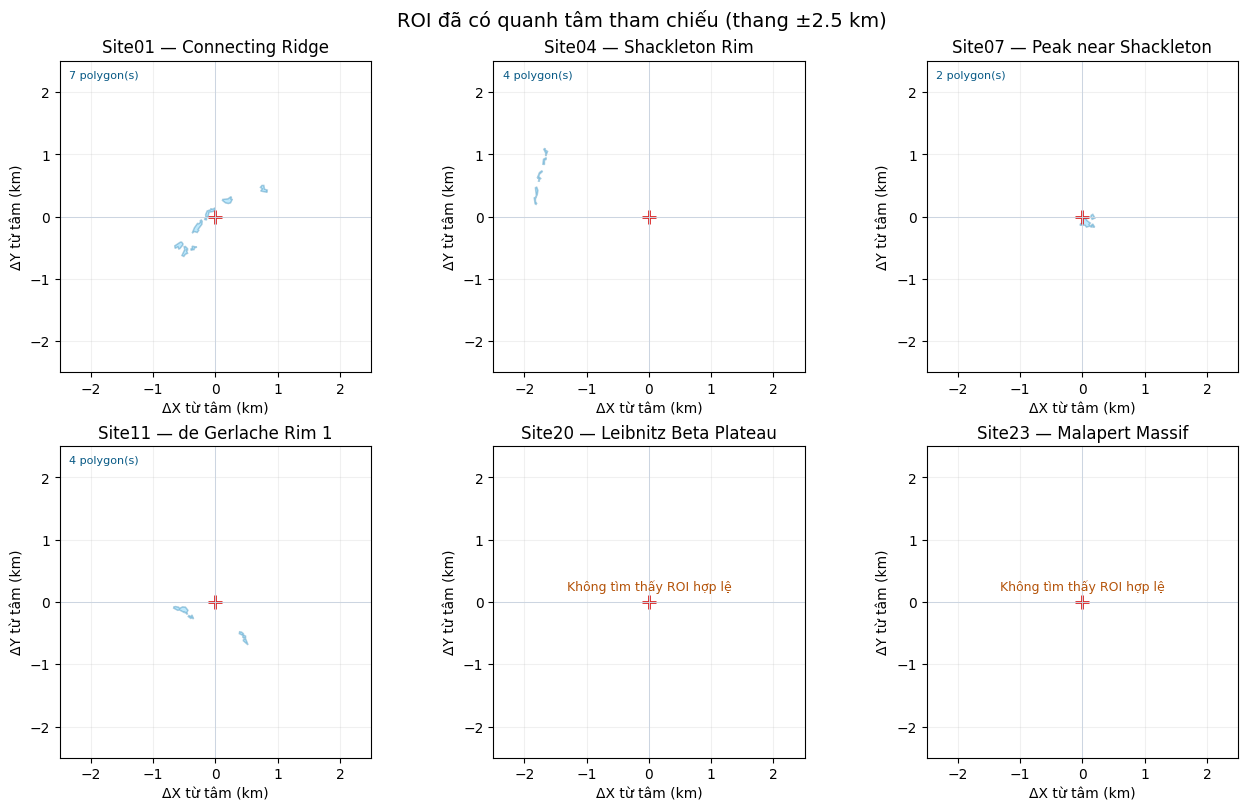

In [4]:
checked_sites=['Site01','Site04','Site07','Site11','Site20','Site23']
fig, axes = plt.subplots(2,3,figsize=(13,8),layout='constrained')
for ax, site in zip(axes.flat,checked_sites):
    r=next(x for x in regions if x['site']==site)
    ax.axhline(0,color='#cbd5e1',lw=.7); ax.axvline(0,color='#cbd5e1',lw=.7)
    if site in roi_polygons:
        for coords in roi_polygons[site]:
            rel=[((x-r['x_m'])/1000,(y-r['y_m'])/1000) for x,y in coords]
            ax.add_patch(MplPolygon(rel,closed=True,facecolor='#38bdf8',edgecolor='#0369a1',alpha=.32,lw=1.1))
        ax.text(.03,.97,f"{len(roi_polygons[site])} polygon(s)",transform=ax.transAxes,va='top',fontsize=8,color='#075985')
    else:
        note='Không tìm thấy ROI hợp lệ' if site in ('Site20','Site23') else 'Không có pixel ROI để vẽ'
        ax.text(.5,.55,note,ha='center',va='center',transform=ax.transAxes,fontsize=9,color='#b45309',wrap=True)
    ax.scatter([0],[0],marker='+',s=100,c='#dc2626',linewidths=2,label='tâm tham chiếu')
    ax.set(title=f"{site} — {r['name']}",xlabel='ΔX từ tâm (km)',ylabel='ΔY từ tâm (km)',xlim=(-2.5,2.5),ylim=(-2.5,2.5),aspect='equal')
    ax.grid(alpha=.18)
fig.suptitle('ROI đã có quanh tâm tham chiếu (thang ±2.5 km)',fontsize=14)
plt.show()

## 3. So sánh khối lượng bộ 5 lớp

Dùng kích thước HTTP HEAD của năm lớp cốt lõi (LDEM, LDEC, slope, sai số Z, sai số slope). Site20v2 được để riêng làm lựa chọn phiên bản; các thanh này không cho biết footprints có cùng diện tích hay coverage đủ cho horizon.

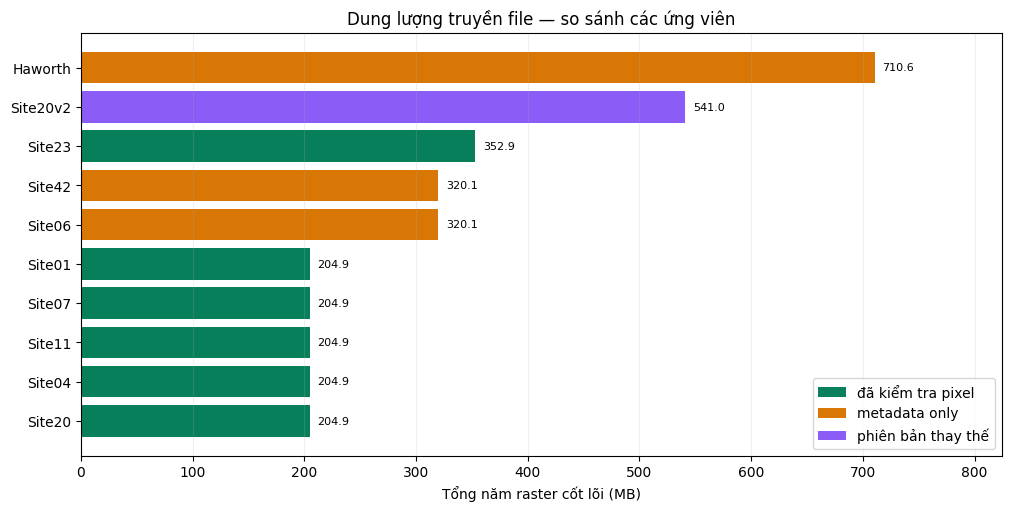

In [5]:
volume_rows=[r for r in regions]
volume_rows.append({'site':'Site20v2','name':'Site20 — bản mở rộng','mb':540.964449,'point':False})
vol=pd.DataFrame(volume_rows).sort_values('mb')
colors=['#087f5b' if s in [r['site'] for r in regions if r['point']] else '#d97706' for s in vol['site']]
colors=[('#8b5cf6' if s=='Site20v2' else c) for s,c in zip(vol['site'],colors)]
fig,ax=plt.subplots(figsize=(10,5),layout='constrained')
y=range(len(vol)); ax.barh(list(y),vol['mb'],color=colors)
ax.set_yticks(list(y),vol['site']); ax.set_xlabel('Tổng năm raster cốt lõi (MB)'); ax.set_title('Dung lượng truyền file — so sánh các ứng viên')
ax.grid(axis='x',alpha=.2)
ax.legend(handles=[Patch(facecolor='#087f5b',label='đã kiểm tra pixel'),Patch(facecolor='#d97706',label='metadata only'),Patch(facecolor='#8b5cf6',label='phiên bản thay thế')],loc='lower right',frameon=True)
for yi,val in zip(y,vol['mb']): ax.text(val+7,yi,f'{val:.1f}',va='center',fontsize=8)
ax.set_xlim(0, max(vol['mb'])*1.16)
plt.show()

## 4. P95 khác biệt chân trời 80 m so với 20 m

Đây là số liệu exploratory đã báo cáo cho **bốn site ban đầu** trên bán kính 25 km, không phải phép thử cho các ứng viên bổ sung. **Chưa tái lập p95; các lần mở rộng profile có bất nhất chưa giải thích.** Notebook nhập các giá trị tổng hợp rồi vẽ, không tính horizon từ DEM. Biểu đồ được giữ để truy vết lịch sử, không chứng minh site nào đạt yêu cầu. 20 m không phải ground truth; các đường 5°/7° và màu sắc chỉ minh họa phép so sánh số, **không dùng để chốt ngưỡng, độ phân giải hoặc bán kính** trước khi đối chiếu phương pháp/profile gốc.

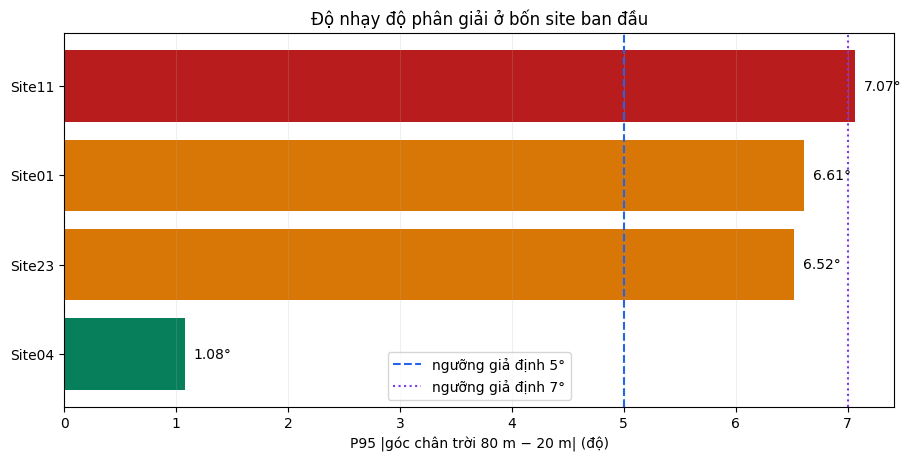

In [6]:
p95=pd.DataFrame([('Site01',6.609),('Site04',1.076),('Site11',7.065),('Site23',6.524)],columns=['Site','P95_abs_diff_deg']).sort_values('P95_abs_diff_deg')
fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
colors=['#087f5b' if v<=5 else '#d97706' if v<=7 else '#b91c1c' for v in p95['P95_abs_diff_deg']]
ax.barh(p95['Site'],p95['P95_abs_diff_deg'],color=colors)
ax.axvline(5,color='#2563eb',linestyle='--',label='ngưỡng giả định 5°')
ax.axvline(7,color='#7c3aed',linestyle=':',label='ngưỡng giả định 7°')
ax.set(xlabel='P95 |góc chân trời 80 m − 20 m| (độ)',title='Độ nhạy độ phân giải ở bốn site ban đầu')
ax.grid(axis='x',alpha=.2); ax.legend()
for y,v in enumerate(p95['P95_abs_diff_deg']): ax.text(v+.08,y,f'{v:.2f}°',va='center')
plt.show()

## Gợi ý đọc hình

- **Màu xanh** trên bản đồ: đã qua kiểm tra 9×9 pixel tại tâm tham chiếu ở local 5 m và regional 80/20 m. Đây chưa phải coverage của toàn ROI.
- **Màu cam**: mới xác nhận có sản phẩm và kích thước, chưa kiểm tra pixel window.
- ROI có sẵn chỉ cho bốn site, và các panel cho thấy tâm Data Book không đại diện cho một điểm đã được nhóm phê duyệt.
- Hình dung roster và nhu cầu nhiệm vụ trước; chọn điểm quan sát/ROI phù hợp. Cần giải thích bất nhất và tái lập profile trước khi dùng p95 đã báo cáo để chốt ngưỡng hoặc phạm vi dữ liệu. Nghiên cứu/tính toán mới cần phạm vi được cho phép riêng.

**Không có site, ROI, độ phân giải hoặc footprint nào được notebook tự động chọn.**